# Week 1 - Assignment 06: Clustering with K-Means

## Objective
To apply unsupervised learning using the K-Means clustering algorithm to identify patterns in the CDC Diabetes Health Indicators dataset.

## Tasks
1. Select numeric features.
2. Scale the selected features.
3. Apply K-Means clustering with k=3.
4. Use the elbow method to choose the number of clusters.
5. Interpret and name the clusters.
6. Evaluate the usefulness of the discovered clusters.

## Step 2: Import Required Libraries

Install and import the libraries required for data loading, preprocessing, visualization and K-Means clustering.

In [1]:
!pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

## Step 3: Load the CDC Diabetes Health Indicators Dataset

Load the CDC Diabetes Health Indicators dataset from the UCI Machine Learning Repository and combine its features and target columns into one DataFrame.

In [2]:
dataset = fetch_ucirepo(id=891)

df = pd.concat(
    [dataset.data.features, dataset.data.targets],
    axis=1
)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (253680, 22)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


## Step 4: Select Numeric Features

Select BMI, physical health days and mental health days for clustering. These three numeric features will be used to identify groups of similar health profiles.

In [3]:
features = ["BMI", "PhysHlth", "MentHlth"]

X = df[features].copy()

print("Selected Features:")
display(X.head())

print("\nFeature Summary:")
display(X.describe())

Selected Features:


,BMI,PhysHlth,MentHlth
0,40,15,18
1,25,0,0
2,28,30,30
3,27,0,0
4,24,0,3



Feature Summary:


,BMI,PhysHlth,MentHlth
count,253680.000000,253680.000000,253680.000000
mean,28.382364,4.242081,3.184772
std,6.608694,8.717951,7.412847
min,12.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000
75%,31.000000,3.000000,2.000000
max,98.000000,30.000000,30.000000


## Step 5: Feature Scaling

Apply StandardScaler to standardize BMI, physical health days and mental health days.

Scaling ensures that all selected features contribute fairly to the distance-based K-Means clustering algorithm.

In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

print("Scaled Feature Data:")
display(X_scaled_df.head())

print("\nScaled Feature Means:")
print(X_scaled_df.mean().round(4))

Scaled Feature Data:


,BMI,PhysHlth,MentHlth
0,1.757936,1.233999,1.998592
1,-0.511806,-0.486592,-0.429630
2,-0.057858,2.954590,3.617407
3,-0.209174,-0.486592,-0.429630
4,-0.663122,-0.486592,-0.024926



Scaled Feature Means:
BMI        -0.0
PhysHlth    0.0
MentHlth    0.0
dtype: float64


## Step 6: Apply K-Means Clustering (k=3)

Apply the K-Means algorithm with three clusters to the scaled health indicators.

Each data point will be assigned to one of three clusters based on its similarity to other data points.

In [5]:
kmeans = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

df["cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster Assignment:")
display(df[features + ["cluster"]].head())

print("\nNumber of Records in Each Cluster:")
print(df["cluster"].value_counts().sort_index())

Cluster Assignment:


,BMI,PhysHlth,MentHlth,cluster
0,40,15,18,2
1,25,0,0,1
2,28,30,30,2
3,27,0,0,1
4,24,0,3,1



Number of Records in Each Cluster:
cluster
0     23919
1    209897
2     19864
Name: count, dtype: int64


## Step 7: Cluster Visualization

Create a scatter plot to visualize the three clusters generated by K-Means.

Different colours represent different clusters, helping us observe how the health profiles are grouped.

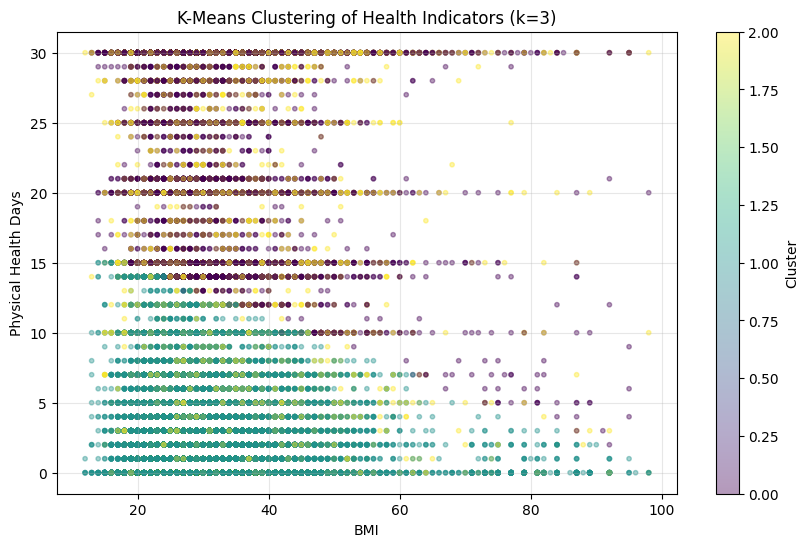

In [6]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["BMI"],
    df["PhysHlth"],
    c=df["cluster"],
    cmap="viridis",
    alpha=0.4,
    s=10
)

plt.title("K-Means Clustering of Health Indicators (k=3)")
plt.xlabel("BMI")
plt.ylabel("Physical Health Days")
plt.colorbar(label="Cluster")
plt.grid(alpha=0.3)
plt.show()


## Step 8: Elbow Method

Apply K-Means with different cluster counts from 2 to 8.

Calculate the inertia for each value of k and use the elbow plot to identify a suitable number of clusters.

In [7]:
inertias = []
k_values = range(2, 9)

for k in k_values:
    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    km.fit(X_scaled)
    inertias.append(km.inertia_)

print("Inertia Values:")

for k, inertia in zip(k_values, inertias):
    print(f"k = {k}: {inertia:.2f}")

Inertia Values:
k = 2: 484638.78
k = 3: 363267.02
k = 4: 256320.37
k = 5: 216957.32
k = 6: 179283.43
k = 7: 156361.67
k = 8: 141674.93


## Step 10: Selecting the Optimal Number of Clusters

Based on the elbow method, k=4 is selected as a reasonable number of clusters.

The inertia decreases substantially from k=2 to k=4. After k=4, the reduction becomes smaller, indicating diminishing improvements from adding more clusters.

In [8]:
optimal_k = 4

final_kmeans = KMeans(
    n_clusters=optimal_k,
    n_init=10,
    random_state=42
)

df["cluster"] = final_kmeans.fit_predict(X_scaled)

print("Selected Number of Clusters:", optimal_k)
print("\nCluster Distribution:")
print(df["cluster"].value_counts().sort_index())

Selected Number of Clusters: 4

Cluster Distribution:
cluster
0     57710
1    155337
2     19071
3     21562
Name: count, dtype: int64


## Step 11: Analyze Cluster Characteristics

Calculate the average BMI, physical health days and mental health days for each cluster.

These averages help us understand the characteristics of each group and assign meaningful human-readable names.

In [9]:
cluster_summary = df.groupby("cluster")[features].mean().round(2)

print("Average Health Indicators for Each Cluster:")
display(cluster_summary)

Average Health Indicators for Each Cluster:


,BMI,PhysHlth,MentHlth
cluster,,,
0,35.98,1.60,1.36
1,25.20,1.00,1.06
2,29.92,13.99,26.54
3,29.60,26.01,2.68


cluster_summary = df.groupby("cluster")[features].mean().round(2)

print("Average Health Indicators for Each Cluster:")
display(cluster_summary)

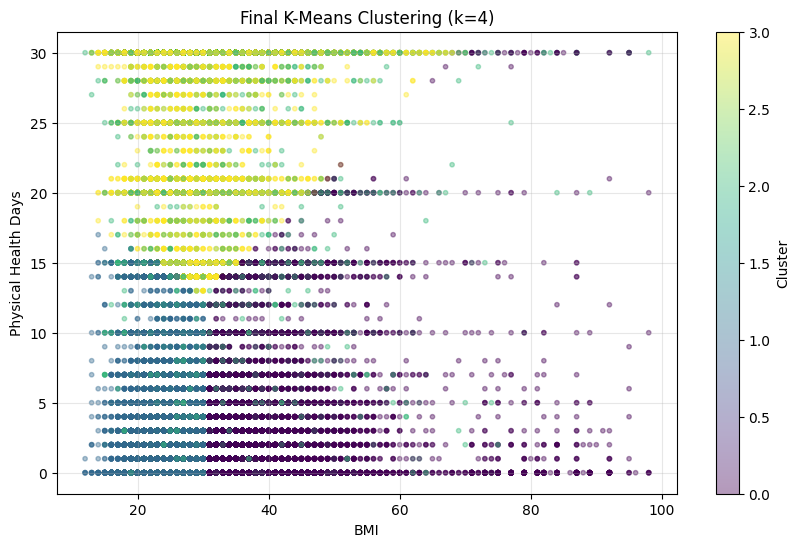

In [10]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["BMI"],
    df["PhysHlth"],
    c=df["cluster"],
    cmap="viridis",
    alpha=0.4,
    s=10
)

plt.title("Final K-Means Clustering (k=4)")
plt.xlabel("BMI")
plt.ylabel("Physical Health Days")
plt.colorbar(label="Cluster")
plt.grid(alpha=0.3)
plt.show()

## Step 13: Naming the Clusters

Examine the average BMI, physical health days and mental health days for each cluster.

Use these values to assign meaningful human-readable names to the four groups.

In [11]:
cluster_summary = df.groupby("cluster")[features].mean().round(2)

for cluster_id, row in cluster_summary.iterrows():
    print(f"\nCluster {cluster_id}")
    print(f"Average BMI: {row['BMI']}")
    print(f"Average Physical Health Days: {row['PhysHlth']}")
    print(f"Average Mental Health Days: {row['MentHlth']}")


Cluster 0
Average BMI: 35.98
Average Physical Health Days: 1.6
Average Mental Health Days: 1.36

Cluster 1
Average BMI: 25.2
Average Physical Health Days: 1.0
Average Mental Health Days: 1.06

Cluster 2
Average BMI: 29.92
Average Physical Health Days: 13.99
Average Mental Health Days: 26.54

Cluster 3
Average BMI: 29.6
Average Physical Health Days: 26.01
Average Mental Health Days: 2.68


## Step 14: Cluster Naming and Interpretation

Based on the average feature values, the four clusters are interpreted as follows:

- Cluster 0: Higher-BMI, fewer reported health-problem days.
- Cluster 1: Lower-BMI, fewer reported health-problem days.
- Cluster 2: Higher physical and mental health difficulties.
- Cluster 3: Higher physical health difficulties, fewer mental health days.

The cluster names describe the average patterns observed in BMI, physical health days and mental health days.

In [12]:
cluster_names = {
    0: "Higher BMI - Fewer Health Problem Days",
    1: "Lower BMI - Fewer Health Problem Days",
    2: "Higher Physical and Mental Health Difficulties",
    3: "Higher Physical Health Difficulties"
}

df["cluster_name"] = df["cluster"].map(cluster_names)

display(
    df[features + ["cluster", "cluster_name"]].head()
)

,BMI,PhysHlth,MentHlth,cluster,cluster_name
0,40,15,18,2,Higher Physical and Mental Health Difficulties
1,25,0,0,1,Lower BMI - Fewer Health Problem Days
2,28,30,30,2,Higher Physical and Mental Health Difficulties
3,27,0,0,1,Lower BMI - Fewer Health Problem Days
4,24,0,3,1,Lower BMI - Fewer Health Problem Days


## Step 15: Usefulness of the Clusters

The K-Means clustering algorithm identified four groups with different average BMI, physical health and mental health patterns. These clusters may help explore general health patterns and support further analysis of population health indicators. However, the clusters are not medical diagnoses, and their usefulness is limited because some groups may overlap and the selected features do not represent a person's complete health condition.